> **Interface update:** the app now uses a custom HTML/CSS/JavaScript frontend and Starlette API. Enter an IPO name and press Predict, or browse historical names. The 103 reserved predictions and metrics below are unchanged. Additional development/training examples are labeled separately and are not additional evaluation results. See `docs/frontend_update.md`.

# Final Evaluation and Historical Demonstration

Part 3 fits the frozen choices on 149 mature development IPOs and evaluates 103 reserved IPOs. No model or threshold selection is performed here. The evaluation receipt preserves the first completed evaluation; subsequent executions verify and reuse it. Prior preparation exposed aggregate full-cohort outcomes, so this period is not claimed as unseen external data.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display, Image, Markdown
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/selected_models.json').exists())
if str(root) not in sys.path: sys.path.insert(0,str(root))
from ipo_prediction.evaluate import run
summary=run()
out=root/'outputs/part3'
display(pd.Series({k:v for k,v in summary.items() if not isinstance(v,(dict,list))},name='Evaluation summary').to_frame())

Reusing recorded evaluation; no fitting or scoring repeated.


,Evaluation summary
part,3
evaluation_status,complete
training_IPOs,149
reserved_IPOs,103
fit_cutoff,2025-01-06 09:00:00+05:30
classification_threshold,0.5
classification_beats_always_apply,False
accuracy_90_percent_reached,False
validation_checks_passed,7
probability_note,"Raw, uncalibrated classifier probabilities"


## Frozen fitting and held-out performance

The price prediction is the selected training-median opening-price/announced-cap ratio times the announced cap. Classification uses the fixed core Random Forest and threshold 0.5. Both pipelines stay fixed over the reserved period. Actual final issue prices are label data only; they never enter X. Historical context may reflect outcomes that became observable earlier in the test period, without test-label model fitting.

,task,model,mae_inr,rmse_inr,mape_pct,n,accuracy,balanced_accuracy,precision_apply,recall_apply,f1_apply,specificity_skip,brier,tn,fp,fn,tp,predicted_apply,predicted_skip
0,regression,selected_price,49.8570,73.4945,14.9687,103,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,regression,announced_cap_baseline,44.9517,98.2171,11.1363,103,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,classification,selected_classifier,NaN,NaN,NaN,103,0.6796,0.5,0.6796,1.0,0.8092,0.0,0.2263,0.0,33.0,0.0,70.0,103.0,0.0
3,classification,always_apply_baseline,NaN,NaN,NaN,103,0.6796,0.5,0.6796,1.0,0.8092,0.0,0.3204,0.0,33.0,0.0,70.0,103.0,0.0


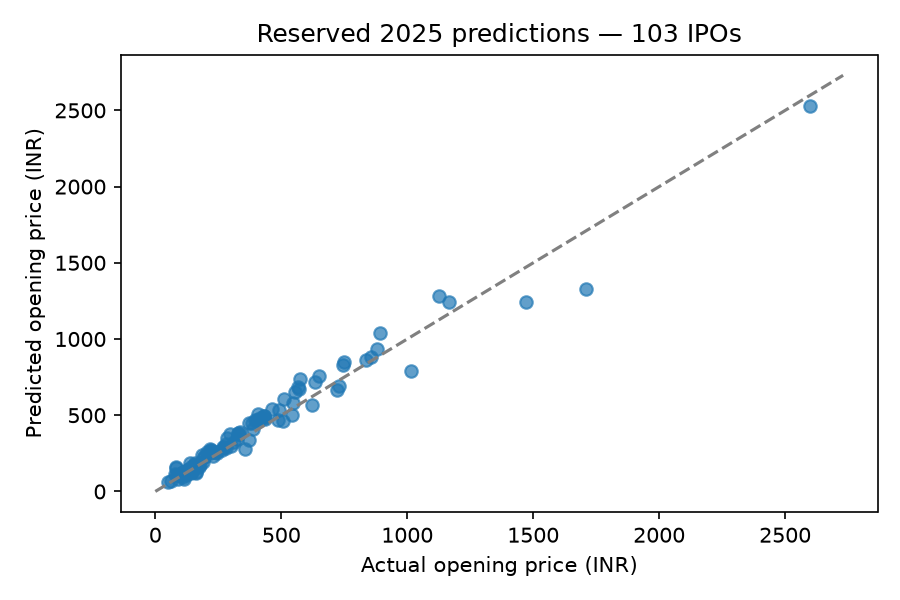

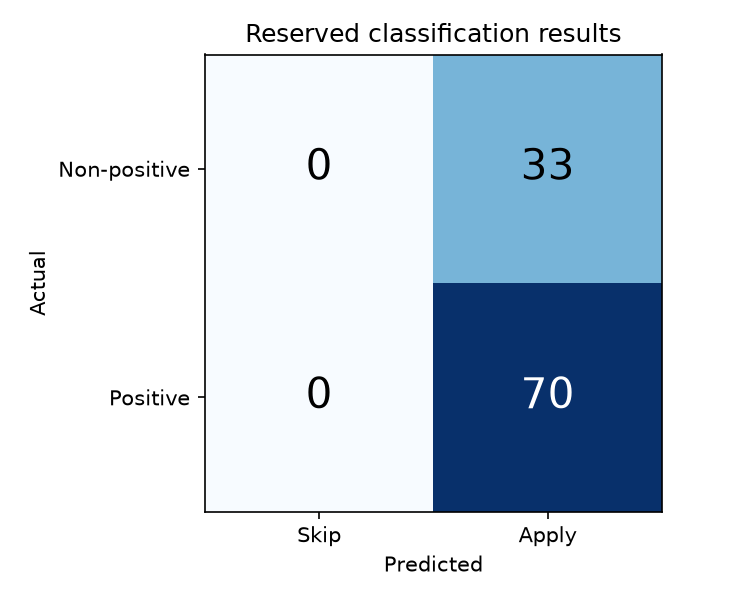

In [2]:
metrics=pd.read_csv(out/'metrics.csv')
display(metrics.dropna(axis=1,how='all').round(4))
display(Image(filename=str(root/'figures/part3/price_predictions.png')))
display(Image(filename=str(root/'figures/part3/confusion_matrix.png')))

## What the classifier establishes

Compare accuracy with always Apply, and inspect the non-positive listings identified correctly. The measured result must not be presented as a 90% result unless the metric reaches it; majority-class accuracy alone does not establish useful Skip decisions. Probabilities are uncalibrated and no allotment or transaction-cost strategy is evaluated.

In [3]:
clf=summary['classification'];base=summary['always_apply_baseline']
print(f"Accuracy: {clf['accuracy']:.2%}; always Apply: {base['accuracy']:.2%}")
print(f"Non-positive listings identified: {clf['tn']} of {clf['tn']+clf['fp']}")
print('Predicted Skip:',clf['predicted_skip'])
print('90% accuracy reached:',summary['accuracy_90_percent_reached'])
display(pd.read_csv(out/'largest_price_errors.csv').head())
display(pd.read_csv(out/'classification_errors.csv').head())

Accuracy: 67.96%; always Apply: 67.96%
Non-positive listings identified: 0 of 33
Predicted Skip: 0
90% accuracy reached: False


,ipo_id,company_name,s0_cutoff_at,predicted_open_inr,positive_gain_probability,predicted_class,signal,listing_open_inr,final_issue_price_inr,target_positive_listing_gain,target_listing_gain_open,label_verification_tier,absolute_error_inr
0,lg-electronics-india-1aa5cb,LG Electronics India Limited,2025-10-07 09:00:00+05:30,1331.137725,0.706662,1,Apply,1710.1,1140.0,1,0.500088,exchange-row snapshot,378.962275
1,corona-remedies-4770be,Corona Remedies Limited,2025-12-08 09:00:00+05:30,1240.059880,0.741782,1,Apply,1470.0,1062.0,1,0.384181,exchange-row snapshot,229.940120
2,aditya-infotech-8ed0aa,Aditya Infotech Limited,2025-07-29 09:00:00+05:30,788.173653,0.809796,1,Apply,1015.0,675.0,1,0.503704,exchange-row snapshot,226.826347
3,travel-food-services-99035c,Travel Food Services Limited,2025-07-07 09:00:00+05:30,1284.431138,0.811710,1,Apply,1125.0,1100.0,1,0.022727,exchange-row snapshot,159.431138
4,ajax-engineering-34ccc3,AJAX Engineering Limited,2025-02-10 09:00:00+05:30,734.461078,0.696360,1,Apply,576.0,629.0,0,-0.084261,exchange-row snapshot,158.461078


,ipo_id,company_name,s0_cutoff_at,predicted_open_inr,positive_gain_probability,predicted_class,signal,listing_open_inr,final_issue_price_inr,target_positive_listing_gain,target_listing_gain_open,label_verification_tier,absolute_error_inr
0,dr-agarwal-s-health-care-5038a8,Dr. Agarwal's Health Care Limited,2025-01-29 09:00:00+05:30,469.401198,0.677931,1,Apply,402.0,402.0,0,0.000000,profile plus separate candle snapshot,67.401198
1,ajax-engineering-34ccc3,AJAX Engineering Limited,2025-02-10 09:00:00+05:30,734.461078,0.696360,1,Apply,576.0,629.0,0,-0.084261,exchange-row snapshot,158.461078
2,aegis-vopak-terminals-cb8487,Aegis Vopak Terminals Limited,2025-05-26 09:00:00+05:30,274.401198,0.759447,1,Apply,220.0,235.0,0,-0.063830,exchange-row snapshot,54.401198
3,schloss-bangalore-a76781,Schloss Bangalore Limited,2025-05-26 09:00:00+05:30,507.934132,0.772573,1,Apply,406.0,435.0,0,-0.066667,exchange-row snapshot,101.934132
4,scoda-tubes-23a5e5,Scoda Tubes Limited,2025-05-28 09:00:00+05:30,163.473054,0.888915,1,Apply,140.0,140.0,0,0.000000,exchange-row snapshot,23.473054


## Reproducibility and demo

Saved final pipelines contain exact training IDs, ordered features, cutoff and threshold. Reload verification reproduced all held-out predictions. The demo uses saved reserved predictions and places actual outcomes in a separate evaluation view. Run `.venv/bin/python -m uvicorn app.server:app --host 127.0.0.1 --port 8501` from the project root. The historical demonstration accepts the 103 held-out IPOs, not unvalidated live IPO data.

In [4]:
display(pd.read_csv(out/'validation_checks.csv'))
pred=pd.read_parquet(out/'heldout_predictions.parquet')
display(pred.head())
assert len(pred)==103
assert 'final_issue_price_inr' not in pred
receipt=json.loads((out/'evaluation_receipt.json').read_text())
print('Recorded artifact hashes:',len(receipt['artifact_sha256']))
display(Markdown((root/'docs/part3_findings.md').read_text()))

,check,passed
0,Frozen inputs/code and versions verified,True
1,149 mature training labels before first test c...,True
2,103 disjoint reserved IPO predictions,True
3,Both saved pipelines reproduce held-out predic...,True
4,Only frozen settings used; threshold remains 0.5,True
5,Positive finite price predictions,True
6,"Probability values in [0,1]",True


,ipo_id,company_name,s0_cutoff_at,predicted_open_inr,positive_gain_probability,predicted_class,signal
0,standard-glass-lining-technology-7de754,Standard Glass Lining Technology Limited,2025-01-06 09:00:00+05:30,163.473054,0.739284,1,Apply
1,quadrant-future-tek-0d0c0d,Quadrant Future Tek Limited,2025-01-07 09:00:00+05:30,338.622754,0.738266,1,Apply
2,laxmi-dental-61673f,Laxmi Dental Limited,2025-01-13 09:00:00+05:30,499.760479,0.683153,1,Apply
3,stallion-india-fluorochemicals-96bec9,Stallion India Fluorochemicals Limited,2025-01-16 09:00:00+05:30,105.089820,0.817568,1,Apply
4,denta-water-infra-solutions-c512ce,Denta Water and Infra Solutions Limited,2025-01-22 09:00:00+05:30,343.293413,0.751140,1,Apply


Recorded artifact hashes: 15


# Final chronological evaluation

The frozen choices were fitted on 149 development IPOs using labels available before 2025-01-06 09:00:00+05:30. Both fitted pipelines stayed fixed for all 103 reserved IPOs. Historical context inputs can reflect already observable past outcomes; no test-label fitting or tuning occurs.

Price MAE: INR 49.86; RMSE: INR 73.49; MAPE: 14.97%. Announced-cap baseline MAE: INR 44.95. The selected price method is the training-median-premium baseline, not a learned forest.

Classifier accuracy: 67.96%; balanced accuracy: 50.00%; Apply precision: 67.96%; recall: 100.00%; F1: 0.8092. Always-Apply accuracy: 67.96%. Confusion counts: TN=0, FP=33, FN=0, TP=70. Apply predictions: 103; Skip predictions: 0.

90% accuracy reached: False. Better accuracy than always Apply: False. Report these measured results without treating the class imbalance as useful Skip detection. Probabilities are uncalibrated. Apply means predicted positive listing gain before costs and without allotment; no investment-profit claim is supported.

The local historical demonstration uses saved reserved predictions, with actual outcomes in a separate evaluation view. Models were reloaded and reproduced the recorded predictions. Reruns reuse the evaluation receipt and do not fit or score again. Changes to recorded inputs/artifacts fail verification.

Limitations remain: small sample, incomplete financial coverage, cohort-limited manager history, assumptions about source publication availability, and one weaker label-verification tier. Prior data preparation displayed aggregate full-cohort outcomes, so this reserved period is not described as unseen external data. Separate price and classification outputs have different targets and can disagree. No model settings or threshold were changed after evaluation. Submission packaging remains Part 4.
